# 03 — Escape dynamics: drift, diffusion, and mean first-passage times

Reproduces **§2.4–2.7** of *"Deepening before dissolution: non-monotonic escape dynamics
in the scaling exponents of county economies"*: construction of the multi-factor SAAI
field variable, transition-pair pooling within Fokker–Planck periods, binned
Kramers–Moyal estimation of drift and diffusion, the corrected escape observables
(path barrier ΔV and Gardiner mean first-passage time), the parametric Euler
pseudo-likelihood estimator with likelihood-ratio tests, county-block bootstrap
intervals (read from pre-computed tables), and the demonstration that the post-policy
window is not identifiable because of selective panel attrition.

In [1]:
import os, sys
sys.path.insert(0, '/home/yushentang/EconP-release')
os.chdir('/home/yushentang/EconP-release')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data_merger import load_panel
from src.saai import compute_saai
from src.fokker_planck import (build_transition_pairs, estimate_kramers_moyal,
                               compute_escape_observables, find_drift_zeros,
                               analyze_diffusion_heterogeneity)
from src.km_mle import lrt_periods, derived_observables
from src.config import FP_PERIODS

print("FP periods:", FP_PERIODS)

/home/yushentang/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


FP periods: {'pre': (2000, 2012), 'during': (2013, 2019), 'post': (2020, 2023)}


## 1. The multi-factor SAAI

The Scaling-Adjusted Anomaly Index is the standardized residual of a year-by-year
log–log regression of gross agricultural output on population and cultivated area
(Eq. 3): SAAI$_i(t) = [\ln Y_i - (\alpha_t + \beta_t \ln N_i + \gamma_t \ln A_i)]/\sigma_t$.
Because each annual cross-section is standardized by its own dispersion, the SAAI
measures a county's position relative to the contemporaneous scaling benchmark.

The dynamics below use the pinned analysis panel (`panel_scaling`). The descriptive
clustering statistic quoted in §2.4 (poverty counties cluster at $\xi \approx -0.4$)
is computed on the full coverage panel, which is also shown for reference. Only
aggregate statistics are printed.

In [2]:
panel = load_panel("panel_scaling")
saai_multi = compute_saai(panel, y_col="GrossOutputValue",
                          x_cols=["PopNum", "CultivateArea"])
print(f"Multi-factor SAAI (analysis panel): {len(saai_multi):,} county-years, "
      f"{saai_multi['CountyCode'].nunique():,} counties, "
      f"years {int(saai_multi['Year'].min())}-{int(saai_multi['Year'].max())}")

pov_flags = panel[["Year", "CountyCode", "IsPoverty"]]
sm = saai_multi.merge(pov_flags, on=["Year", "CountyCode"], how="left")
g = sm.groupby(sm["IsPoverty"].astype(bool))["SAAI"].mean()
print(f"  analysis panel:  mean SAAI poverty = {g[True]:+.2f}, "
      f"non-poverty = {g[False]:+.2f}")

panel_cov = load_panel("panel_full")
saai_cov = compute_saai(panel_cov, y_col="GrossOutputValue",
                        x_cols=["PopNum", "CultivateArea"])
sc = saai_cov.merge(panel_cov[["Year", "CountyCode", "IsPoverty"]],
                    on=["Year", "CountyCode"], how="left")
gc = sc.groupby(sc["IsPoverty"].astype(bool))["SAAI"].mean()
print(f"  coverage panel:  mean SAAI poverty = {gc[True]:+.2f}, "
      f"non-poverty = {gc[False]:+.2f}")
print("  paper reports: poverty -0.39 vs non-poverty +0.24 "
      "(poverty counties cluster at xi ~ -0.4)")

Loaded: /home/yushentang/EconP-release/data_clean/panel_scaling.parquet (19,392 rows, 64 cols)
Multi-factor SAAI (analysis panel): 10,278 county-years, 1,394 counties, years 2000-2023
  analysis panel:  mean SAAI poverty = -0.44, non-poverty = +0.25
Loaded: /home/yushentang/EconP-release/data_clean/panel_full.parquet (38,308 rows, 64 cols)
  coverage panel:  mean SAAI poverty = -0.39, non-poverty = +0.24
  paper reports: poverty -0.39 vs non-poverty +0.24 (poverty counties cluster at xi ~ -0.4)


## 2. Transition pairs by Fokker–Planck period

One-year transition pairs $(\xi_t, \xi_{t+1})$ are pooled across **all** counties
within each period (pre 2000–2012, during 2013–2019, post 2020–2023); only consecutive
years contribute. The multi-factor pair counts fall sharply after 2019 because
cultivated-area coverage collapses in the post window.

In [3]:
pairs = {p: build_transition_pairs(saai_multi, p) for p in FP_PERIODS}
paper_counts = {"pre": 5860, "during": 1734, "post": 91}
for p in FP_PERIODS:
    print(f"{p:>7}: {len(pairs[p]):>6,} pairs, "
          f"{pairs[p]['CountyCode'].nunique():>5,} counties   "
          f"(paper reports: {paper_counts[p]:,})")

    pre:  5,860 pairs, 1,272 counties   (paper reports: 5,860)
 during:  1,734 pairs,   472 counties   (paper reports: 1,734)
   post:     91 pairs,    71 counties   (paper reports: 91)


## 3. Binned Kramers–Moyal estimation (§2.5–2.6)

Conditional first and second moments of the one-year increments, on 25 equal-width
bins over the 1st–99th percentile support; bins with fewer than 30 pairs are marked
unreliable. Two quantities summarize the regime change:

* the **drift attractor** $\xi^*$ — the stable zero of $\hat A(\xi)$;
* the **B-ratio** — mean diffusion on the poverty side ($\xi<0$) over the
  non-poverty side ($\xi>0$). Poverty-side noise is compressed during the campaign.

In [4]:
km = {p: estimate_kramers_moyal(pairs[p], n_bins=25, period=p)
      for p in ("pre", "during")}

paper_km = {"pre":    {"xi": -0.26, "br": 1.551, "p": None},
            "during": {"xi": -0.70, "br": 0.556, "p": 0.017}}
for p in ("pre", "during"):
    stable = [z for z in find_drift_zeros(km[p]) if z["type"] == "stable"]
    dh = analyze_diffusion_heterogeneity(km[p])
    print(f"{p:>7}: xi* = {stable[0]['xi']:+.3f} (paper: {paper_km[p]['xi']:+.2f});  "
          f"B-ratio = {dh['ratio']:.3f} (paper: {paper_km[p]['br']:.3f});  "
          f"t-test p = {dh['t_pvalue']:.3f}"
          + ("  (paper: 0.017)" if p == "during" else ""))

    pre: xi* = -0.258 (paper: -0.26);  B-ratio = 1.551 (paper: 1.551);  t-test p = 0.276
 during: xi* = -0.700 (paper: -0.70);  B-ratio = 0.556 (paper: 0.556);  t-test p = 0.017  (paper: 0.017)


## 4. Corrected escape observables and the effective potential (§2.7)

With the escape target at the scaling benchmark $\xi = 0$:
$V_{\mathrm{FP}} = -\int A/B\,d\xi$; the barrier $\Delta V$ is the highest point of
$V_{\mathrm{FP}}$ on the path from $\xi^*$ to the target, minus $V_{\mathrm{FP}}(\xi^*)$;
$\tau_{\mathrm{MFPT}}$ is the full Gardiner double integral with an absorbing boundary
at the target and a reflecting boundary at the far edge of the support. The well
**deepens** during the campaign — the intervention slows escape in the short run.

In [5]:
esc = {p: compute_escape_observables(km[p]) for p in ("pre", "during")}
paper_esc = {"pre": (0.023, 2.8), "during": (0.154, 11.7)}
for p in ("pre", "during"):
    dV_p, tau_p = paper_esc[p]
    print(f"{p:>7}: dV = {esc[p]['delta_V']:.3f} (paper: {dV_p:.3f});  "
          f"tau_MFPT = {esc[p]['tau_mfpt']:.1f} yr (paper: {tau_p:.1f} yr);  "
          f"id_status = {esc[p]['id_status']}")

    pre: dV = 0.023 (paper: 0.023);  tau_MFPT = 2.8 yr (paper: 2.8 yr);  id_status = stable_zero
 during: dV = 0.154 (paper: 0.154);  tau_MFPT = 11.7 yr (paper: 11.7 yr);  id_status = stable_zero


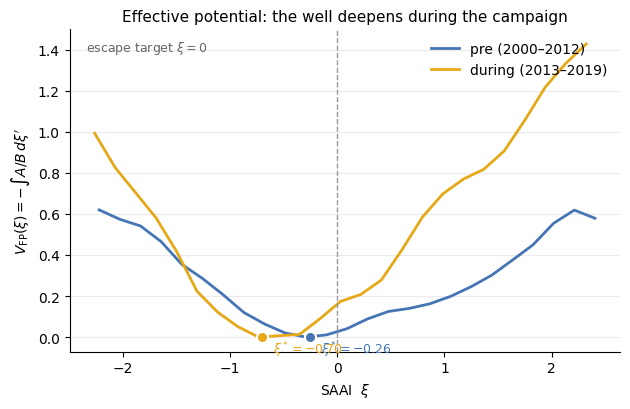

In [6]:
COL = {"pre": "#4575b4", "during": "#e6a817"}
LAB = {"pre": "pre (2000\u20132012)", "during": "during (2013\u20132019)"}

fig, ax = plt.subplots(figsize=(6.4, 4.2))
for p in ("pre", "during"):
    ax.plot(esc[p]["V_fp_xi"], esc[p]["V_fp"], color=COL[p], lw=2, label=LAB[p])
    ax.plot(esc[p]["xi_trap"], np.interp(esc[p]["xi_trap"],
            esc[p]["V_fp_xi"], esc[p]["V_fp"]), "o", ms=8, color=COL[p],
            mec="white", mew=1.5, zorder=5)
    ax.annotate(f"$\\xi^*={esc[p]['xi_trap']:+.2f}$",
                (esc[p]["xi_trap"], np.interp(esc[p]["xi_trap"],
                 esc[p]["V_fp_xi"], esc[p]["V_fp"])),
                textcoords="offset points", xytext=(8, -12),
                color=COL[p], fontsize=9)
ax.axvline(0.0, color="0.6", lw=1, ls="--")
ax.text(0.03, 0.97, "escape target $\\xi=0$", transform=ax.transAxes,
        fontsize=9, color="0.4", va="top")
ax.set_xlabel(r"SAAI  $\xi$")
ax.set_ylabel(r"$V_{\mathrm{FP}}(\xi) = -\int A/B\, d\xi'$")
ax.set_title("Effective potential: the well deepens during the campaign", fontsize=11)
ax.legend(frameon=False, loc="upper right")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="0.92", lw=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## 5. Parametric MLE and likelihood-ratio tests (§2.7)

The parametric estimator fits an Euler pseudo-likelihood with cubic drift and
log-quadratic diffusion (7 parameters per period), pooling the full sample instead
of binning. Regime change between pre and during is tested by likelihood ratio:
any change (7 df), drift-only change (4 df), diffusion-only change (3 df).
The $\chi^2$ p-values are approximate under within-county dependence; the primary
uncertainty statements are the bootstrap intervals in §6.

In [7]:
lrt = lrt_periods({p: pairs[p] for p in ("pre", "during")})
paper_lrt = {"any_change": "4e-20", "drift_change": "7e-7",
             "diffusion_change": "9e-16"}
for test in ("any_change", "drift_change", "diffusion_change"):
    r = lrt[test]
    print(f"{test:>17}: LR = {r['LR']:7.2f}, df = {r['df']}, "
          f"p = {r['p_chi2']:.2e}   (paper reports: p ~ {paper_lrt[test]})")

print()
paper_mle = {"pre": (0.005, 0.05), "during": (0.084, 1.05)}
for p in ("pre", "during"):
    d = derived_observables(lrt["fit_" + p]["params"],
                            pairs[p]["xi_t"].to_numpy())
    dV_p, g_p = paper_mle[p]
    print(f"{p:>7} MLE: dV = {d['delta_V']:.3f} (paper: {dV_p:.3f});  "
          f"Gamma = {d['gamma']:.2f} (paper: {g_p:.2f});  "
          f"tau_MFPT = {d['tau_mfpt']:.1f} yr")

       any_change: LR =  106.93, df = 7, p = 3.98e-20   (paper reports: p ~ 4e-20)
     drift_change: LR =   34.00, df = 4, p = 7.46e-07   (paper reports: p ~ 7e-7)
 diffusion_change: LR =   73.23, df = 3, p = 8.68e-16   (paper reports: p ~ 9e-16)

    pre MLE: dV = 0.005 (paper: 0.005);  Gamma = 0.05 (paper: 0.05);  tau_MFPT = 1.9 yr
 during MLE: dV = 0.084 (paper: 0.084);  Gamma = 1.05 (paper: 1.05);  tau_MFPT = 7.4 yr


## 6. Bootstrap confidence intervals (pre-computed)

The county-block bootstrap ($B = 1{,}000$ resamples of whole county trajectories)
is a heavy computation and is **not rerun here**; the tables below were generated by
`scripts/run_escape_dynamics.py` (seeds 102/103 for the binned estimator, 106 for
the MLE) and are read from `results/tables/`. The paired MLE bootstrap resamples
counties once per draw and evaluates both periods on the same resample, so the
during-minus-pre contrasts respect the within-county dependence.

The headline uncertainty statements: the barrier **increase** is
$\Delta V_{\mathrm{during}} - \Delta V_{\mathrm{pre}} = +0.079$ $[0.029, 0.154]$,
and the escape time roughly quadruples, $\tau$ ratio $4.0\times$ $[1.4, 45]$.

In [8]:
# Full regeneration (heavy, ~hours):
# python3 scripts/run_escape_dynamics.py --steps counts,km

ci = pd.read_csv("results/tables/km_bootstrap_ci.csv")
sub = ci[(ci.saai_spec == "multi") & ci.period.isin(["pre", "during"])
         & ci.quantity.isin(["delta_V", "tau_mfpt", "B_ratio"])]
print("Binned-KM bootstrap (multi-factor SAAI), 95% percentile CIs:")
for _, r in sub.iterrows():
    print(f"  {r['period']:>7} {r['quantity']:>9}: median {r['boot_median']:8.3f}  "
          f"[{r['ci_lo']:.3f}, {r['ci_hi']:.3f}]")

mb = pd.read_csv("results/tables/mle_bootstrap.csv")
print("\nPaired MLE bootstrap, during vs pre:")
for q in ("delta_V (during-pre)", "tau_mfpt (during/pre)",
          "gamma (during-pre)", "B_ratio_w (during/pre)"):
    r = mb[mb.quantity == q].iloc[0]
    print(f"  {q:>22}: {r['median']:6.3f}  [{r['ci_lo']:.3f}, {r['ci_hi']:.3f}]")

r = mb[mb.quantity == "delta_V (during-pre)"].iloc[0]
print(f"\npaper reports: dV difference +0.079 [0.029, 0.154] -> "
      f"{r['median']:+.3f} [{r['ci_lo']:.3f}, {r['ci_hi']:.3f}]")
r = mb[mb.quantity == "tau_mfpt (during/pre)"].iloc[0]
print(f"paper reports: tau ratio 4.0x [1.4, 45]        -> "
      f"{r['median']:.1f}x [{r['ci_lo']:.1f}, {r['ci_hi']:.1f}]")

Binned-KM bootstrap (multi-factor SAAI), 95% percentile CIs:
      pre   delta_V: median    0.018  [-0.002, 0.077]
      pre  tau_mfpt: median    4.256  [1.305, 13.804]
      pre   B_ratio: median    1.478  [0.942, 2.548]
   during   delta_V: median    0.091  [-0.004, 0.285]
   during  tau_mfpt: median   15.046  [6.267, 29.079]
   during   B_ratio: median    0.550  [0.400, 0.774]

Paired MLE bootstrap, during vs pre:
    delta_V (during-pre):  0.079  [0.029, 0.154]
   tau_mfpt (during/pre):  4.040  [1.446, 45.256]
      gamma (during-pre):  1.022  [0.355, 2.106]
  B_ratio_w (during/pre):  0.592  [0.450, 0.763]

paper reports: dV difference +0.079 [0.029, 0.154] -> +0.079 [0.029, 0.154]
paper reports: tau ratio 4.0x [1.4, 45]        -> 4.0x [1.4, 45.3]


## 7. The post-policy window is not identifiable

Two independent failures. First, the multi-factor post panel is simply too thin:
91 pairs spread over 25 bins leave **zero** bins above the 30-pair reliability
threshold. Second — and more fundamental — the post-period estimates are contaminated
by selective attrition. Both diagnostics are recomputed live below; the attrition
diagnostics use the **single-factor** SAAI, which retains post-period coverage
(1,331 pairs, 701 counties) and therefore isolates the attrition mechanism from the
thin-sample problem.

In [9]:
km_post = estimate_kramers_moyal(pairs["post"], n_bins=25, period="post")
print(f"post (multi): {km_post.n_pairs_total} pairs, "
      f"{int(km_post.reliable.sum())} reliable bins out of "
      f"{len(km_post.bin_centers)} (rule: >= 30 pairs per bin)")

saai_single = compute_saai(panel, y_col="GrossOutputValue", x_cols=["PopNum"])
present = saai_single.groupby("Year")["CountyCode"].apply(set)
dropouts = present[2020] - present[2021]
drop_mean = saai_single[(saai_single.Year == 2020)
                        & saai_single.CountyCode.isin(dropouts)]["SAAI"].mean()
print(f"\nCounties in the 2020 cross-section that exit by 2021: n = {len(dropouts)}")
print(f"Their mean SAAI in 2020 = {drop_mean:+.2f}   (paper reports: -0.46)")

pairs_single = {p: build_transition_pairs(saai_single, p) for p in FP_PERIODS}
print("\nMean one-year SAAI increment by period (single-factor):")
for p in FP_PERIODS:
    note = "  (paper reports: +0.059)" if p == "post" else \
           "  (paper reports: magnitude ~0.01)"
    print(f"  {p:>7}: {pairs_single[p]['delta_xi'].mean():+.4f}{note}")

post (multi): 91 pairs, 0 reliable bins out of 25 (rule: >= 30 pairs per bin)

Counties in the 2020 cross-section that exit by 2021: n = 153
Their mean SAAI in 2020 = -0.46   (paper reports: -0.46)

Mean one-year SAAI increment by period (single-factor):
      pre: +0.0129  (paper reports: magnitude ~0.01)
   during: -0.0102  (paper reports: magnitude ~0.01)
     post: +0.0589  (paper reports: +0.059)


### Why attrition manufactures pseudo-drift

The SAAI is standardized **within each annual cross-section**: by construction the
cross-sectional mean is zero every year. If exit from the panel were random, the
surviving counties' increments would still average near zero. But exit after 2020 is
strongly selective — the counties that leave sit far below the benchmark
(mean SAAI $\approx -0.46$). Removing the low tail forces the survivors to be
re-centred around the new, higher cross-sectional mean, which mechanically pushes
every survivor's standardized score down relative to where the *old* composition
would have placed it — and, symmetrically, makes the observed year-over-year
increments of the survivors systematically positive. The post-period mean increment
(+0.059) is roughly five times the pre/during magnitudes ($\pm 0.01$): a signature
of composition change, not of dynamics. Any drift or potential estimated from these
pairs therefore reflects who left the panel, not how counties move — which is why
the paper reports the post-policy escape dynamics as an open question and carries
the post-2020 narrative with distribution-level evidence instead.

### Summary of reproduced quantities

| Quantity | Paper | This notebook |
|---|---|---|
| SAAI means (poverty / non-poverty) | −0.39 / +0.24 | recomputed above |
| Transition pairs (pre / during / post) | 5,860 / 1,734 / 91 | recomputed |
| Drift attractor $\xi^*$ (pre → during) | −0.26 → −0.70 | recomputed |
| B-ratio (pre → during) | 1.551 → 0.556 (p = 0.017) | recomputed |
| Binned ΔV, τ (pre) | 0.023, 2.8 yr | recomputed |
| Binned ΔV, τ (during) | 0.154, 11.7 yr | recomputed |
| LRT p-values (any / drift / diffusion) | ~4e−20 / 7e−7 / 9e−16 | recomputed |
| MLE ΔV, Γ (pre; during) | 0.005, 0.05; 0.084, 1.05 | recomputed |
| Paired bootstrap ΔV difference | +0.079 [0.029, 0.154] | read from table |
| Paired bootstrap τ ratio | 4.0× [1.4, 45] | read from table |
| Exit-county mean SAAI (2020→21) | −0.46 | recomputed |
| Post mean increment | +0.059 vs ±0.01 | recomputed |